<a href="https://colab.research.google.com/github/katt-05/dl/blob/main/chapter03_introduction_to_ml_frameworks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is a companion notebook for the book [Deep Learning with Python, Third Edition](https://www.manning.com/books/deep-learning-with-python-third-edition). For readability, it only contains runnable code blocks and section titles, and omits everything else in the book: text paragraphs, figures, and pseudocode.

**If you want to be able to follow what's going on, I recommend reading the notebook side by side with your copy of the book.**

The book's contents are available online at [deeplearningwithpython.io](https://deeplearningwithpython.io).

In [ ]:
!pip install keras keras-hub --upgrade -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 12.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.32.0 which is incompatible.


In [ ]:
import os
os.environ["KERAS_BACKEND"] = "jax"

In [ ]:
# @title
import os
from IPython.core.magic import register_cell_magic

@register_cell_magic
def backend(line, cell):
    current, required = os.environ.get("KERAS_BACKEND", ""), line.split()[-1]
    if current == required:
        get_ipython().run_cell(cell)
    else:
        print(
            f"This cell requires the {required} backend. To run it, change KERAS_BACKEND to "
            f"\"{required}\" at the top of the notebook, restart the runtime, and rerun the notebook."
        )

## Introduction to TensorFlow, PyTorch, JAX, and Keras

### A brief history of deep learning frameworks

### How these frameworks relate to each other

### Introduction to TensorFlow

#### First steps with TensorFlow

##### Tensors and variables in TensorFlow

###### Constant tensors

In [ ]:
import tensorflow as tf
tf.ones(shape=(2, 1)) #모든 원소 1인 텐서 생성

<tf.Tensor: shape=(2, 1), dtype=float32, numpy=
array([[1.],
       [1.]], dtype=float32)>

In [ ]:
tf.zeros(shape=(2, 1))

In [ ]:
tf.constant([1, 2, 3], dtype="float32") #상수 텐서 생성

<tf.Tensor: shape=(3,), dtype=float32, numpy=array([1., 2., 3.], dtype=float32)>

###### Random tensors

In [ ]:
x = tf.random.normal(shape=(3, 1), mean=0., stddev=1.)
print(x) #정규분포 따르는 난수, N(0,1^2)

In [ ]:
x = tf.random.uniform(shape=(3, 1), minval=0., maxval=1.)
print(x)

###### Tensor assignment and the Variable class

In [ ]:
import numpy as np

x = np.ones(shape=(2, 2))
x[0, 0] = 0.0 # x의 1생 1열 값을 0.0으로 변경

In [ ]:
v = tf.Variable(initial_value=tf.random.normal(shape=(3, 1)))
print(v) #변수 텐서를 생성/ 정규분포 난수 생성-.3행 1열 크기로 설정

<tf.Variable 'Variable:0' shape=(3, 1) dtype=float32, numpy=
array([[ 2.5309753],
       [-1.1276407],
       [ 1.0057962]], dtype=float32)>


In [ ]:
v.assign(tf.ones((3, 1))) # 새로운 값으로 덮어씌워 할당

<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[1.],
       [1.],
       [1.]], dtype=float32)>

In [ ]:
v[0, 0].assign(3.)

<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[3.],
       [1.],
       [1.]], dtype=float32)>

In [ ]:
v.assign_add(tf.ones((3, 1)))

##### Tensor operations: Doing math in TensorFlow

In [ ]:
a = tf.ones((2, 2))
b = tf.square(a)
c = tf.sqrt(a)
d = b + c
e = tf.matmul(a, b)
f = tf.concat((a, b), axis=0)

In [ ]:
def dense(inputs, W, b):#가중치 함수 정의
    return tf.nn.relu(tf.matmul(inputs, W) + b) #입력 데이터*가중치행렬+편향
    #matmul결과에 relu함수 적용->음수값은 0으로  양수는 그대로

##### Gradients in TensorFlow: A second look at the GradientTape API

In [ ]:
input_var = tf.Variable(initial_value=3.0) #초기값 3.0인 변수텐서 생성
with tf.GradientTape() as tape: #연산 과정 기록
    result = tf.square(input_var)  #input_var^2
gradient = tape.gradient(result, input_var)#기록된 연산 바탕으로 기울기 계산
print(gradient)

tf.Tensor(6.0, shape=(), dtype=float32)


In [ ]:
input_const = tf.constant(3.0) #3 상수텐서 생성
with tf.GradientTape() as tape:
    tape.watch(input_const) #연산 과정 추적 지시
    result = tf.square(input_const) #input_const^2
gradient = tape.gradient(result, input_const) #기울기 계산
print(gradient)

tf.Tensor(6.0, shape=(), dtype=float32)


In [ ]:
time = tf.Variable(0.0) #초기값 0.0인 시간 변수 생성
with tf.GradientTape() as outer_tape: #내부 테이프 연산과정 포함 속도 시간으로 미분
    with tf.GradientTape() as inner_tape: #내부 테이프: 위치 시간으로 미분 속도계산
        position = 4.9 * time**2  #위치함수
    speed = inner_tape.gradient(position, time) #속도 함수 (1차 미분)
acceleration = outer_tape.gradient(speed, time) #가속도 함수(2차 미분)

##### Making TensorFlow functions fast using compilation

In [ ]:
@tf.function #연산 속도 향상
def dense(inputs, W, b):
    return tf.nn.relu(tf.matmul(inputs, W) + b)

In [ ]:
@tf.function(jit_compile=True)#기본 그래프 컴파일 기능+ jit기능 활성화
def dense(inputs, W, b):
    return tf.nn.relu(tf.matmul(inputs, W) + b)

#### An end-to-end example: A linear classifier in pure TensorFlow

In [ ]:
import numpy as np

num_samples_per_class = 1000 #각 그룹당 생성할 데이터 수 1000개로 지정
negative_samples = np.random.multivariate_normal(#다변량 정규분포 따르는 난수 생성
    mean=[0, 3], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)
positive_samples = np.random.multivariate_normal(
    mean=[3, 0], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)

In [ ]:
inputs = np.vstack((negative_samples, positive_samples)).astype(np.float32)
#두개이상의 배열을 수직으로 결합->negativesample+positivesample
#결합된 배열 데이터 32비트 부동소수점으로 합침
print(inputs)

[[-0.8658591   2.014617  ]
 [ 0.9212781   3.1215036 ]
 [ 0.22942789  2.7716444 ]
 ...
 [ 3.920081    1.2503436 ]
 [ 2.9734035  -0.09050352]
 [ 1.4896162  -1.5629729 ]]


In [ ]:
targets = np.vstack(#수직으로 합쳐 target벡터로 만듦
    (
        np.zeros((num_samples_per_class, 1), dtype="float32"),
        #모든 원소 0인 1000행 1열 배열
        np.ones((num_samples_per_class, 1), dtype="float32"),
        #모든 원소 1인 1000행 1열 배열
    )
)
print(targets)

[[0.]
 [0.]
 [0.]
 ...
 [1.]
 [1.]
 [1.]]


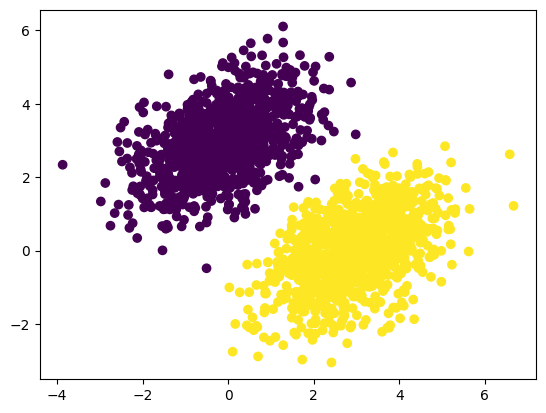

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(inputs[:, 0], inputs[:, 1], c=targets[:, 0])
#inputs[:, 0] 모든 행에서 1열x 값 #inputs[:, 1] 모든 행에서 2열y 값
c=targets[:, 0]#각 점의 색상 지정
plt.show()

In [ ]:
input_dim = 2
output_dim = 1
W = tf.Variable(initial_value=tf.random.uniform(shape=(input_dim, output_dim)))
#가중치 변수 생성: 0-1 균등분포에서 무작위 생성 (2행 1열)
b = tf.Variable(initial_value=tf.zeros(shape=(output_dim,)))
#편향 생성: 모든 원소 0인 1차원 크기로 초기화

In [ ]:
def model(inputs, W, b):
    return tf.matmul(inputs, W) + b #모델 설정

In [ ]:
def mean_squared_error(targets, predictions): #mse계산
    per_sample_losses = tf.square(targets - predictions)
    #정답과 예측값 차이 구함->샘플별 제곱
    return tf.reduce_mean(per_sample_losses)
    #계산된 모든 샘플별 손실값 평균을 구하여 최종 손실값으로 반환

In [ ]:
learning_rate = 0.1 #학습률 설정

@tf.function(jit_compile=True)
def training_step(inputs, targets, W, b):
    with tf.GradientTape() as tape:#순전파 과정 발생 연산 기록
        predictions = model(inputs, W, b) #가중치 편향으로 모델 예측값 계산
        loss = mean_squared_error(predictions, targets) #예측값 정답 사이의 손실(mse)계산
    grad_loss_wrt_W, grad_loss_wrt_b = tape.gradient(loss, [W, b]) #가중치와 편향의 기울기 각각 구함
    W.assign_sub(grad_loss_wrt_W * learning_rate) #기울기에 학습률 곱한 만큼 기존 가중치와 편향에서 빼줌
    b.assign_sub(grad_loss_wrt_b * learning_rate) #
    return loss

In [ ]:
for step in range(40): #모델 가중치 학습 과정 40번 반복
    loss = training_step(inputs, targets, W, b) #학습 단계 함수 호출
    #예측, 오차, 기울기 및 가중치 업데이트 한 번 실행 후 손실 값 받아옴
    print(f"Loss at step {step}: {loss:.4f}")
    #각 스텝별 손실 출력

Loss at step 0: 0.2568
Loss at step 1: 0.0844
Loss at step 2: 0.0753
Loss at step 3: 0.0705
Loss at step 4: 0.0665
Loss at step 5: 0.0629
Loss at step 6: 0.0596
Loss at step 7: 0.0566
Loss at step 8: 0.0539
Loss at step 9: 0.0514
Loss at step 10: 0.0491
Loss at step 11: 0.0471
Loss at step 12: 0.0452
Loss at step 13: 0.0435
Loss at step 14: 0.0419
Loss at step 15: 0.0405
Loss at step 16: 0.0392
Loss at step 17: 0.0380
Loss at step 18: 0.0369
Loss at step 19: 0.0359
Loss at step 20: 0.0350
Loss at step 21: 0.0342
Loss at step 22: 0.0334
Loss at step 23: 0.0327
Loss at step 24: 0.0321
Loss at step 25: 0.0316
Loss at step 26: 0.0310
Loss at step 27: 0.0306
Loss at step 28: 0.0301
Loss at step 29: 0.0298
Loss at step 30: 0.0294
Loss at step 31: 0.0291
Loss at step 32: 0.0288
Loss at step 33: 0.0285
Loss at step 34: 0.0283
Loss at step 35: 0.0280
Loss at step 36: 0.0278
Loss at step 37: 0.0276
Loss at step 38: 0.0275
Loss at step 39: 0.0273


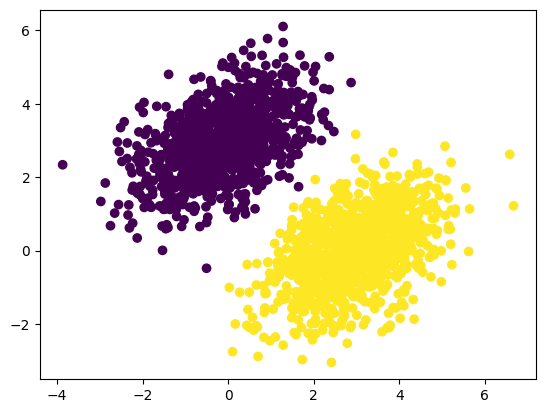

In [ ]:
predictions = model(inputs, W, b)
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)
plt.show()

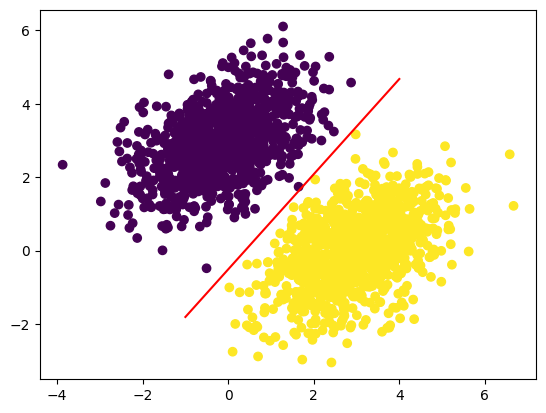

In [ ]:
x = np.linspace(-1, 4, 100) #x축 방향 값 -1부터 4까지 균등하게 생성
y = -W[0] / W[1] * x + (0.5 - b) / W[1] #결정 경계 구함
plt.plot(x, y, "-r")
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)

#### What makes the TensorFlow approach unique

### Introduction to PyTorch

#### First steps with PyTorch

##### Tensors and parameters in PyTorch

###### Constant tensors

In [ ]:
import torch
torch.ones(size=(2, 1))#모든 원소가 1로 채워진 1열 2행 1열 크기 텐서 생성

tensor([[1.],
        [1.]])

In [ ]:
torch.zeros(size=(2, 1))

tensor([[0.],
        [0.]])

In [ ]:
torch.tensor([1, 2, 3], dtype=torch.float32)

tensor([1., 2., 3.])

###### Random tensors

In [ ]:
torch.normal(#정규분포 텐서 생성
mean=torch.zeros(size=(3, 1)),
std=torch.ones(size=(3, 1)))

tensor([[ 0.6101],
        [-0.7805],
        [ 1.3991]])

In [ ]:
torch.rand(3, 1)#균등분포

tensor([[0.9638],
        [0.4222],
        [0.6789]])

###### Tensor assignment and the Parameter class

In [ ]:
x = torch.zeros(size=(2, 1))
x[0, 0] = 1.
x

tensor([[1.],
        [0.]])

In [ ]:
x = torch.zeros(size=(2, 1))
p = torch.nn.parameter.Parameter(data=x) #파이토치 신경망 모델 학습 가능하게 변환

##### Tensor operations: Doing math in PyTorch

In [ ]:
a = torch.ones((2, 2))
b = torch.square(a)
c = torch.sqrt(a)
d = b + c
e = torch.matmul(a, b)
f = torch.cat((a, b), dim=0)

In [ ]:
def dense(inputs, W, b):
    return torch.nn.relu(torch.matmul(inputs, W) + b)

##### Computing gradients with PyTorch

In [ ]:
input_var = torch.tensor(3.0, requires_grad=True) #값 3.0 기울기 계산 추적하도록 설정된 텐서 설정
result = torch.square(input_var) #입력값 제곱
result.backward()#역전파 실행 ->미분값 계산
gradient = input_var.grad #기울기 저장
gradient

tensor(6.)

In [ ]:
result = torch.square(input_var)
result.backward() #pythorch는 새로 계산된 기울기 누적하는 특징 있음
input_var.grad

tensor(12.)

In [ ]:
input_var.grad = None #누적 초기화

#### An end-to-end example: A linear classifier in pure PyTorch

In [ ]:
input_dim = 2
output_dim = 1

W = torch.rand(input_dim, output_dim, requires_grad=True)
#균등분포에서 무작위 값 추출 2행 1열 크기 가중치 텐서 지정
b = torch.zeros(output_dim, requires_grad=True)
#모든 원소 0인 1열 편향 벡터 지정 + 기울기 추적 설정
W
b

tensor([0.], requires_grad=True)

In [ ]:
def model(inputs, W, b):
    return torch.matmul(inputs, W) + b

In [ ]:
def mean_squared_error(targets, predictions):
    per_sample_losses = torch.square(targets - predictions) #정답-예측값에 제곱
    return torch.mean(per_sample_losses)#샘플별 손실값의 평균->최종 손실값

In [ ]:
learning_rate = 0.1 #학습률 설정

def training_step(inputs, targets, W, b): #
    predictions = model(inputs) #모델에 입력 데이터 넣어 예측값 계산
    loss = mean_squared_error(targets, predictions) #손실 계산
    loss.backward() #역전파로 계산 그래프 전체 기울기 구함
    grad_loss_wrt_W, grad_loss_wrt_b = W.grad, b.grad #가중치, 편향 기울기 가져옴
    with torch.no_grad(): #연산 역사 기록 차단
        W -= grad_loss_wrt_W * learning_rate #가중치 업데이트
        b -= grad_loss_wrt_b * learning_rate #편향 업데이트
    W.grad = None #기울기 중첩 초기화
    b.grad = None
    return loss

##### Packaging state and computation with the Module class

In [ ]:
class LinearModel(torch.nn.Module):
    def __init__(self):
        super().__init__() #torch.nn.Module초기화 매서드 호출
        self.W = torch.nn.Parameter(torch.rand(input_dim, output_dim))
        #0-1 무작위 값으로가중치 텐서 생성. 학습 가능한 매개변수로 등록
        self.b = torch.nn.Parameter(torch.zeros(output_dim))
        #0으로 채워진 편향 텐서 등록

    def forward(self, inputs): #순전파 연산 정의
        return torch.matmul(inputs, self.W) + self.b #연산 반환

In [ ]:
model = LinearModel() #객체 인스턴스 생성

In [ ]:
torch_inputs = torch.tensor(inputs) #input을 텐서로 변환
output = model(torch_inputs)
#정의된 선형모델 인스턴스에 입력 텐서 전달-<순전파 연산 수행
torch_inputs
output

tensor([[ 1.4465],
        [ 2.4145],
        [ 2.0988],
        ...,
        [ 1.2390],
        [ 0.1597],
        [-1.0596]], grad_fn=<AddBackward0>)

In [ ]:
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [ ]:
def training_step(inputs, targets):
    predictions = model(inputs) #입력 데이터 모델에 통과시켜 예측값 계산 수행
    loss = mean_squared_error(targets, predictions) #손실 값 계산
    loss.backward() #역전파로 그래프 전체 기울기
    optimizer.step() #옵티마이저가 기울기 바탕으로 파라미터 업데이트
    model.zero_grad() #기울기 누적되지 않도록 초기화
    return loss

##### Making PyTorch modules fast using compilation

In [ ]:
compiled_model = torch.compile(model)

In [ ]:
@torch.compile
def dense(inputs, W, b):
    return torch.nn.relu(torch.matmul(inputs, W) + b)

#### What makes the PyTorch approach unique

텐서플로우와 달리 파이토치는 역전파알고리즘에서 계산된 기울기가 누적됨

### Introduction to JAX

#### First steps with JAX

#### Tensors in JAX

In [ ]:
from jax import numpy as jnp
jnp.ones(shape=(2, 1))

Array([[1.],
       [1.]], dtype=float32)

In [ ]:
jnp.zeros(shape=(2, 1))

Array([[0.],
       [0.]], dtype=float32)

In [ ]:
jnp.array([1, 2, 3], dtype="float32")

#### Random number generation in JAX

In [ ]:
np.random.normal(size=(3,))

array([ 0.87474202, -1.23886169, -0.68204258])

In [ ]:
np.random.normal(size=(3,))

In [ ]:
def apply_noise(x, seed):
    np.random.seed(seed) #시드 값 고정->재현성 확보
    x = x * np.random.normal((3,)) #정규분포 무작위 난수 x와 곱해
    return x

seed = 1337
seed += 1
z = apply_noise(x, seed)

/tmp/ipykernel_1734/2654806653.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  x = x * np.random.normal((3,))


In [ ]:
import jax

seed_key = jax.random.key(1337) #키 객체 생성

In [ ]:
seed_key = jax.random.key(0) #키를 0이라는 시드값으로 생성
jax.random.normal(seed_key, shape=(3,)) #시드 키 활용하여 정규분포 난수 생성

Array([ 1.6226422 ,  2.0252647 , -0.43359444], dtype=float32)

In [ ]:
seed_key = jax.random.key(123)
jax.random.normal(seed_key, shape=(3,))

In [ ]:
jax.random.normal(seed_key, shape=(3,))

In [ ]:
seed_key = jax.random.key(123)
jax.random.normal(seed_key, shape=(3,))

In [ ]:
new_seed_key = jax.random.split(seed_key, num=1)[0]
#독립적 난수 키 분할->1번째 키 추출
jax.random.normal(new_seed_key, shape=(3,)) #새로운 시드 키로 정규분포 난수 생성

##### Tensor assignment

In [ ]:
x = jnp.array([1, 2, 3], dtype="float32")
new_x = x.at[0].set(10) #인덱스 값 변경

##### Tensor operations: Doing math in JAX

In [ ]:
a = jnp.ones((2, 2))
b = jnp.square(a)
c = jnp.sqrt(a)
d = b + c
e = jnp.matmul(a, b)
e *= d

In [ ]:
def dense(inputs, W, b):
    return jax.nn.relu(jnp.matmul(inputs, W) + b)

##### Computing gradients with JAX

In [ ]:
def compute_loss(input_var):
    return jnp.square(input_var) #입력값 제곱 결과

In [ ]:
grad_fn = jax.grad(compute_loss) #손실함수의 기울기 계산

In [ ]:
input_var = jnp.array(3.0)
grad_of_loss_wrt_input_var = grad_fn(input_var)
#입력값 전달하여 손실함수 기울기 계산 후 결과를 변수에 저장

##### JAX gradient-computation best practices

###### Returning the loss value

In [ ]:
grad_fn = jax.value_and_grad(compute_loss)
output, grad_of_loss_wrt_input_var = grad_fn(input_var)

###### Getting gradients for a complex function

###### Returning auxiliary outputs

##### Making JAX functions fast with @jax.jit

In [ ]:
@jax.jit
def dense(inputs, W, b):
    return jax.nn.relu(jnp.matmul(inputs, W) + b)

#### An end-to-end example: A linear classifier in pure JAX

In [ ]:
def model(inputs, W, b):
    return jnp.matmul(inputs, W) + b

def mean_squared_error(targets, predictions):
    per_sample_losses = jnp.square(targets - predictions)
    return jnp.mean(per_sample_losses)

In [ ]:
def compute_loss(state, inputs, targets):
    W, b = state
    predictions = model(inputs, W, b)
    loss = mean_squared_error(targets, predictions)
    return loss

In [ ]:
grad_fn = jax.value_and_grad(compute_loss)

In [ ]:
learning_rate = 0.1

@jax.jit
def training_step(inputs, targets, W, b):
    loss, grads = grad_fn((W, b), inputs, targets) #가중치 편향에서 손실 기울기 동시 계산
    grad_wrt_W, grad_wrt_b = grads #계산된 기울기*학습률로 새 모수로 갱신
    W = W - grad_wrt_W * learning_rate
    b = b - grad_wrt_b * learning_rate
    return loss, W, b

In [ ]:
input_dim = 2
output_dim = 1

W = jax.numpy.array(np.random.uniform(size=(input_dim, output_dim)))
b = jax.numpy.array(np.zeros(shape=(output_dim,)))
state = (W, b) # 튜블 하나의 형태로 묶어 관리
for step in range(40): #학습 40번 반복으로 최적화
    loss, W, b = training_step(inputs, targets, W, b)
    print(f"Loss at step {step}: {loss:.4f}")

TypeError: compute_loss() takes 1 positional argument but 3 were given

#### What makes the JAX approach unique

### Introduction to Keras

#### First steps with Keras

##### Picking a backend framework

In [ ]:
import os

os.environ["KERAS_BACKEND"] = "jax"

import keras

#### Layers: The building blocks of deep learning

##### The base `Layer` class in Keras

In [ ]:
import keras

class SimpleDense(keras.Layer): #밀집된 층 정의
    def __init__(self, units, activation=None): #활성화함수를 받아 초기화
        super().__init__()  #내부 속성 세팅
        self.units = units #뉴런 갯수 저장
        self.activation = activation #활성화 함수 저장

    def build(self, input_shape): #가중치, 편향 변수 자동생성
        batch_dim, input_dim = input_shape
        #입력 텐서 형태를 특성 차원으로 분리하여 가졍ㅗㅁ
        self.W = self.add_weight(
            shape=(input_dim, self.units), initializer="random_normal"
        ) #가중치 행렬 생성
        self.b = self.add_weight(shape=(self.units,), initializer="zeros")
        #모든 값 0으로 초기화하는 편향 행렬 생성

    def call(self, inputs): #순전파 연산
        y = keras.ops.matmul(inputs, self.W) + self.b
        if self.activation is not None:
            y = self.activation(y)
        return y

In [ ]:
my_dense = SimpleDense(units=32, activation=keras.ops.relu)
input_tensor = keras.ops.ones(shape=(2, 784))
#배치 크기 2, 특성 차원 784인 모든 원소1 입력 텐서
output_tensor = my_dense(input_tensor)
#입력텐서를 mydense에 통과시킴
print(output_tensor.shape)

(2, 32)


##### Automatic shape inference: Building layers on the fly

In [ ]:
from keras import layers

layer = layers.Dense(32, activation="relu")

In [ ]:
from keras import models
from keras import layers

model = models.Sequential(
    [
        layers.Dense(32, activation="relu"),
        layers.Dense(32),
    ]
)

In [ ]:
model = keras.Sequential(
    [
        SimpleDense(32, activation="relu"),
        SimpleDense(64, activation="relu"),
        SimpleDense(32, activation="relu"),
        SimpleDense(10, activation="softmax"),
    ]
)

#### From layers to models

#### The "compile" step: Configuring the learning process

In [ ]:
model = keras.Sequential([keras.layers.Dense(1)])
model.compile(# 모델이 학습 수행할 수 있게 설정 완
    optimizer="rmsprop",
    loss="mean_squared_error",
    metrics=["accuracy"],
)

In [ ]:
model.compile(
    optimizer=keras.optimizers.RMSprop(),
    loss=keras.losses.MeanSquaredError(),
    metrics=[keras.metrics.BinaryAccuracy()],
)

#### Picking a loss function

#### Understanding the fit method

In [ ]:
history = model.fit(#준비된 데이터로 가중치 실제로 학습시키는 매서드
    inputs,
    targets,
    epochs=5,
    batch_size=128,
)

Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.0075 - loss: 12.0313
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0075 - loss: 11.6093
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0075 - loss: 11.2484
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0075 - loss: 10.8997
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0075 - loss: 10.5615    


In [ ]:
history.history

{'accuracy': [0.007500000298023224,
  0.007500000298023224,
  0.007500000298023224,
  0.007500000298023224,
  0.007500000298023224],
 'loss': [12.031255722045898,
  11.609299659729004,
  11.248448371887207,
  10.899660110473633,
  10.561473846435547]}

#### Monitoring loss and metrics on validation data

In [ ]:
model = keras.Sequential([keras.layers.Dense(1)])
model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.1),
    loss=keras.losses.MeanSquaredError(),
    metrics=[keras.metrics.BinaryAccuracy()], #성능 측정 지시
)

indices_permutation = np.random.permutation(len(inputs)) #전체 인덱스 섞음
shuffled_inputs = inputs[indices_permutation] #정답 레이블 같이 섞음
shuffled_targets = targets[indices_permutation]

num_validation_samples = int(0.3 * len(inputs))
#30프로를 검증 데이터(validationdata)로 쓰기 위해 개수 계산
val_inputs = shuffled_inputs[:num_validation_samples] # 30프로 검증용으로 분리
val_targets = shuffled_targets[:num_validation_samples]
training_inputs = shuffled_inputs[num_validation_samples:] # 70프로 학습용으로 분리
training_targets = shuffled_targets[num_validation_samples:]
model.fit(
    training_inputs,
    training_targets,
    epochs=5,
    batch_size=16,
    validation_data=(val_inputs, val_targets),
) #학습 데이터로 모델 학습+검증 데이터로 성능 측

#### Inference: Using a model after training

In [ ]:
predictions = model.predict(val_inputs, batch_size=128)
print(predictions[:10])

In [ ]:
# 모델에 포함된 모든 층의 가중치와 편향 확인하기
for i, layer in enumerate(model.layers):
    weights = layer.get_weights()
    print(f"--- Layer {i} ---")
    print(f"가중치 (Weights - W): \n{weights[0]}") #가중치행렬
    print(f"편향 (Biases - b): \n{weights[1]}") #뉴런별 편향벡터값

--- Layer 0 ---
가중치 (Weights - W): 
[[-0.9390233]
 [ 0.7311184]]
편향 (Biases - b): 
[0.08197049]


Naive 버전: 사용자가 tf.Variable 이나 torch.tensor (또는 jax.numpy.array)를 직접 만들고 전역 변수나 튜플 형태로 관리하기 때문에, 변수(W, b) 자체를 그대로 출력하여 가중치를 확인할 수 있습니다.

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# 시각화하고 싶은 스텝 리스트
target_steps = [5, 10, 15, 20]

for step in range(40):
    loss = training_step(inputs, targets, W, b)

    # 지정한 스텝일 때 현재 결정 경계와 분류 결과 시각화
    if step in target_steps:
        plt.figure(figsize=(6, 4))
        predictions = model(inputs, W, b)

        # 데이터 산점도 및 예측 결과(0.5 기준 분류) 시각화
        plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5, cmap="coolwarm")
        plt.title(f"Classification Results at Step {step} (Loss: {loss:.4f})")
        plt.show()

TypeError: compute_loss() takes 1 positional argument but 3 were given

In [ ]:
#-Try to modify your linear classifier not using bias term (b). Try to fit your model, what happens?
# 편향 b를 제거하고 가중치 W만 사용
input_dim = 2
output_dim = 1
W = tf.Variable(initial_value=tf.random.uniform(shape=(input_dim, output_dim)))

def model_no_bias(inputs, W):
    return tf.matmul(inputs, W)  # b 없이 W와의 행렬 곱만 수행

    # 결정 경계가 무조건 원점을 지남
    #학습 성능 저

In [ ]:
import keras
from keras import layers
import numpy as np

# 1. 2차원 선형 분류 데이터 준비 (앞서 만들었던 inputs, targets 활용)
# (데이터가 아직 없다면 앞선 데이터 생성 셀을 먼저 실행해 주셔야 합니다.)

# 2. Keras Sequential 모델 정의 (편향 포함, 단일 뉴런 Dense 층)
model = keras.Sequential([
    layers.Dense(units=1, activation="sigmoid") # 이진 분류이므로 시그모이드 활성화 함수 사용
])

# 3. 모델 컴파일 (옵티마이저, 손실 함수, 평가 지표 설정)
model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.1),
    loss=keras.losses.BinaryCrossentropy(), # 이진 분류용 손실 함수
    metrics=[keras.metrics.BinaryAccuracy()] # 정확도 지표
)

# 4. 전체 데이터를 학습용과 검증용으로 30% 분할
indices_permutation = np.random.permutation(len(inputs))
shuffled_inputs = inputs[indices_permutation]
shuffled_targets = targets[indices_permutation]

num_validation_samples = int(0.3 * len(inputs))
val_inputs = shuffled_inputs[:num_validation_samples]
val_targets = shuffled_targets[:num_validation_samples]
training_inputs = shuffled_inputs[num_validation_samples:]
training_targets = shuffled_targets[num_validation_samples:]

# 5. fit() 함수를 이용한 모델 학습 및 검증 데이터 모니터링
history = model.fit(
    training_inputs,
    training_targets,
    epochs=5,
    batch_size=16,
    validation_data=(val_inputs, val_targets)
)

tensorflow 실습

In [ ]:
#1. 스칼라 함수 $f(x, y) = x^2 y + xy + 3y$ 의 도함수 구하기 (x = 2, y = 1 기준)
import tensorflow as tf

# 1. 변수 설정 (x = 2.0, y = 1.0)
x = tf.Variable(2.0)
y = tf.Variable(1.0)

# 2. GradientTape을 통한 연산 기록 및 기울기 계산
with tf.GradientTape() as tape:
    f = (x ** 2) * y + x * y + 3 * y

# x와 y에 대한 편미분 구하기 ()
grad_x, grad_y = tape.gradient(f, [x, y])

print(f"df/dx 결과: {grad_x.numpy()}")  # 수식적 미분: 2xy + y = 2(2)(1) + 1 = 5
print(f"df/dy 결과: {grad_y.numpy()}")  # 수식적 미분: x^2 + x + 3 = 4 + 2 + 3 = 9

df/dx 결과: 5.0
df/dy 결과: 9.0


In [ ]:
#주어진 $x, W, b$ 설정 및 $f(W, b) = xW + b$ 에 대한 미분먼저 문제에서 제시한 대로 변수들을 선언합니다.
import numpy as np
import tensorflow as tf

# 주어진 변수 설정
x = tf.constant(np.array([1., 4., 3.]).reshape(1, 3), dtype=tf.float32)
W = tf.Variable(tf.random.uniform((3, 2)), dtype=tf.float32)
b = tf.Variable(tf.zeros((2,)), dtype=tf.float32)

In [ ]:
# $f(W, b) = xW + b$ 에 대한 $W, b$ 미분
with tf.GradientTape() as tape:
    f = tf.matmul(x, W) + b

grad_W, grad_b = tape.gradient(f, [W, b])

print("--- f(W, b) = xW + b 미분 결과 ---")
print(f"df/dW :\n{grad_W.numpy()}")
print(f"df/db :\n{grad_b.numpy()}")

--- f(W, b) = xW + b 미분 결과 ---
df/dW :
[[1. 1.]
 [4. 4.]
 [3. 3.]]
df/db :
[1. 1.]


In [ ]:
#$f(W, b) = (xW + b)^3$ 에 대한 $W, b$ 미분 (힌트: tf.pow() 또는 거듭제곱 연산자 ** 3 사용)
with tf.GradientTape() as tape:
    # 텐서의 모든 원소에 대해 거듭제곱 연산 수행
    f = tf.pow(tf.matmul(x, W) + b, 3)

grad_W_cubed, grad_b_cubed = tape.gradient(f, [W, b])

print("\n--- f(W, b) = (xW + b)^3 미분 결과 ---")
print(f"df/dW :\n{grad_W_cubed.numpy()}")
print(f"df/db :\n{grad_b_cubed.numpy()}")


--- f(W, b) = (xW + b)^3 미분 결과 ---
df/dW :
[[ 91.698906  35.892715]
 [366.79562  143.57086 ]
 [275.0967   107.67815 ]]
df/db :
[91.698906 35.892715]


pytorch에서 같은 연산 수행

In [ ]:
import torch

# 1. PyTorch 텐서 및 파라미터 설정
x_pt = torch.tensor([[1., 4., 3.]], dtype=torch.float32)
W_pt = torch.tensor(torch.rand(3, 2), requires_grad=True)
b_pt = torch.tensor(torch.zeros(2), requires_grad=True)

# --- [첫 번째 함수: f(W, b) = xW + b] ---
f1 = torch.matmul(x_pt, W_pt) + b_pt
# 결과가 스칼라가 아니므로 각 요소의 합을 기준으로 역전파를 수행하기 위해 sum() 사용
f1.sum().backward()

print("--- PyTorch: f(W, b) = xW + b 미분 결과 ---")
print(f"df/dW :\n{W_pt.grad}")
print(f"df/db :\n{b_pt.grad}")

# 기울기 초기화 (누적 방지)
W_pt.grad = None
b_pt.grad = None

# --- [두 번째 함수: f(W, b) = (xW + b)^3] ---
f2 = torch.pow(torch.matmul(x_pt, W_pt) + b_pt, 3)
f2.sum().backward()

print("\n--- PyTorch: f(W, b) = (xW + b)^3 미분 결과 ---")
print(f"df/dW :\n{W_pt.grad}")
print(f"df/db :\n{b_pt.grad}")